In [22]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

#Limites maximos de las coordenadas de los rectangulos
MAX_X = 100
MAX_ALTURA = 50
MIN_ANCHO = 5
MAX_ANCHO = 25

In [23]:
def crear_rectangulos():
    rectangulos = []

    cantidad = int(input("¿Cuántos rectángulos deseas generar? "))

    for _ in range(cantidad):
        # Generar coordenadas aleatorias
        izquierda = random.randint(0, MAX_X - MIN_ANCHO)
        ancho = random.randint(MIN_ANCHO, MAX_ANCHO)

        # Evitar que la coordenada derecha exceda MAX_X
        derecha = min(izquierda + ancho, MAX_X)

        altura = random.randint(1, MAX_ALTURA)

        # Guardar la tripleta (izquierda, altura, derecha)
        rectangulos.append((izquierda, altura, derecha))

    return rectangulos

In [24]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def dibujar_rectangulos(rectangulos):
    if not rectangulos:
        print("No hay rectángulos para dibujar.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))

    for izquierda, altura, derecha in rectangulos:
        ancho = derecha - izquierda

        rectangulo = Rectangle(
            (izquierda, 0),
            ancho,
            altura,
            facecolor="skyblue",
            edgecolor="blue",
            alpha=0.45,
            linewidth=1.5
        )

        ax.add_patch(rectangulo)

    # Calcular los límites a partir de los rectángulos
    min_x = min(r[0] for r in rectangulos)
    max_x = max(r[2] for r in rectangulos)
    max_altura = max(r[1] for r in rectangulos)

    # Añadir un margen del 5 % en X y del 15 % en Y
    margen_x = (max_x - min_x) * 0.05
    margen_y = max_altura * 0.15

    # Evitar márgenes nulos
    margen_x = max(margen_x, 0.5)
    margen_y = max(margen_y, 0.5)

    ax.set_xlim(min_x - margen_x, max_x + margen_x)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar el plano cartesiano
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Rectángulos generados aleatoriamente")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()

In [25]:
def dibujar_contorno(franjas):
    if not franjas:
        print("No hay franjas para dibujar.")
        return

    # Ordenar las franjas por coordenada izquierda
    franjas = sorted(franjas, key=lambda f: f[0])

    # Calcular los límites de las coordenadas
    min_x = min(f[0] for f in franjas)
    max_x = max(f[0] for f in franjas)
    max_altura = max(f[1] for f in franjas)

    # Calcular los márgenes
    margen_x = max((max_x - min_x) * 0.05, 0.5)
    margen_y = max(max_altura * 0.15, 0.5)

    # Crear un espacio de dibujo independiente
    fig, ax = plt.subplots(figsize=(12, 6))

    for izquierda, altura in franjas:
        # Todas las franjas tienen ancho fijo de 1 unidad
        ancho = 1

        if altura > 0:
            franja = Rectangle(
                (izquierda, 0),
                ancho,
                altura,
                facecolor="salmon",
                edgecolor="red",
                alpha=0.5,
                linewidth=1.5
            )

            ax.add_patch(franja)

    # Ajustar los límites para incluir la última franja y sus márgenes
    limite_izquierdo = min_x - margen_x
    limite_derecho = max_x + 1 + margen_x

    ax.set_xlim(limite_izquierdo, limite_derecho)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar etiquetas y presentación
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Contorno formado por Fuerza Bruta")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()

In [26]:
#Algoritmo fuerza bruta
def fuerzaBruta(rectangulos):
    # Crear un diccionario para almacenar la altura máxima en cada coordenada X
    alturas = {}

    # Iterar sobre cada rectángulo
    for izquierda, altura, derecha in rectangulos:
        # Actualizar la altura máxima para cada coordenada X cubierta por el rectángulo
        for x in range(izquierda, derecha):
            if x in alturas:
                alturas[x] = max(alturas[x], altura)
            else:
                alturas[x] = altura

    # Convertir el diccionario de alturas en una lista de franjas (izquierda, altura)
    franjas = sorted(alturas.items())

    return franjas

In [27]:
def DivideYVenceras(rectangulo):
    """
    Genera el contorno de un solo rectángulo.

    Entrada:
        (izquierda, altura, derecha)

    Salida:
        Lista de franjas (izquierda, altura).
    """
    izquierda, altura, derecha = rectangulo

    return [
        (izquierda, altura),
        (derecha, 0)
    ]


def combinar_franjas(franjas_A, franjas_B):
    """
    Combina dos contornos conservando la altura máxima
    en cada intervalo.

    Entrada:
        Dos listas de franjas (x, altura).

    Salida:
        Una lista de franjas que representa el contorno combinado.
    """
    resultado = []

    i = 0
    j = 0

    altura_A = 0
    altura_B = 0
    altura_anterior = 0

    while i < len(franjas_A) and j < len(franjas_B):

        x_A = franjas_A[i][0]
        x_B = franjas_B[j][0]

        # Procesar la siguiente coordenada más pequeña.
        x = min(x_A, x_B)

        # Actualizar todas las alturas que cambian en x.
        if x_A == x:
            altura_A = franjas_A[i][1]
            i += 1

        if x_B == x:
            altura_B = franjas_B[j][1]
            j += 1

        # La altura visible es la máxima de ambos contornos.
        altura_actual = max(altura_A, altura_B)

        # Guardar solo los cambios reales de altura.
        if altura_actual != altura_anterior:
            resultado.append((x, altura_actual))
            altura_anterior = altura_actual

    # Incorporar los puntos restantes de A.
    while i < len(franjas_A):
        x, altura_A = franjas_A[i]
        i += 1

        altura_actual = max(altura_A, altura_B)

        if altura_actual != altura_anterior:
            resultado.append((x, altura_actual))
            altura_anterior = altura_actual

    # Incorporar los puntos restantes de B.
    while j < len(franjas_B):
        x, altura_B = franjas_B[j]
        j += 1

        altura_actual = max(altura_A, altura_B)

        if altura_actual != altura_anterior:
            resultado.append((x, altura_actual))
            altura_anterior = altura_actual

    return resultado


def skyline_divide_venceras(rectangulos):
    """
    Calcula el contorno de un conjunto de rectángulos
    mediante Divide y Vencerás.

    Entrada:
        Lista de tripletas (izquierda, altura, derecha).

    Salida:
        Lista de franjas (izquierda, altura).
    """

    # Caso base: no hay rectángulos.
    if not rectangulos:
        return []

    # Caso base: un solo rectángulo.
    if len(rectangulos) == 1:
        return DivideYVenceras(rectangulos[0])

    # Dividir la colección en dos mitades.
    medio = len(rectangulos) // 2

    izquierda = rectangulos[:medio]
    derecha = rectangulos[medio:]

    # Resolver recursivamente cada mitad.
    franjas_A = skyline_divide_venceras(izquierda)
    franjas_B = skyline_divide_venceras(derecha)

    # Combinar los dos contornos.
    return combinar_franjas(franjas_A, franjas_B)

In [28]:
def dibujar_contorno_divideVenceras(franjas):
    if not franjas:
        print("No hay franjas para dibujar.")
        return

    # Ordenar las franjas por coordenada X
    franjas = sorted(franjas, key=lambda f: f[0])

    # Calcular límites y márgenes
    min_x = min(x for x, altura in franjas)
    max_x = max(x for x, altura in franjas)
    max_altura = max(altura for x, altura in franjas)

    margen_x = max((max_x - min_x) * 0.05, 0.5)
    margen_y = max(max_altura * 0.15, 0.5)

    fig, ax = plt.subplots(figsize=(12, 6))

    # Dibujar cada franja hasta la siguiente coordenada X
    for i in range(len(franjas) - 1):
        izquierda, altura = franjas[i]
        derecha = franjas[i + 1][0]

        ancho = derecha - izquierda

        if ancho > 0 and altura > 0:
            franja = Rectangle(
                (izquierda, 0),
                ancho,
                altura,
                facecolor="salmon",
                edgecolor="red",
                alpha=0.5,
                linewidth=1.5
            )
            ax.add_patch(franja)

    # Ajustar el espacio de dibujo
    ax.set_xlim(min_x - margen_x, max_x + margen_x)
    ax.set_ylim(0, max_altura + margen_y)

    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Contorno mediante Divide y Vencerás")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()


Tripletas almacenadas:
[(21, 2, 44), (10, 46, 15), (17, 35, 42), (10, 41, 16), (82, 18, 95)]

Franjas generadas por el algoritmo de fuerza bruta:
[(10, 46), (11, 46), (12, 46), (13, 46), (14, 46), (15, 41), (17, 35), (18, 35), (19, 35), (20, 35), (21, 35), (22, 35), (23, 35), (24, 35), (25, 35), (26, 35), (27, 35), (28, 35), (29, 35), (30, 35), (31, 35), (32, 35), (33, 35), (34, 35), (35, 35), (36, 35), (37, 35), (38, 35), (39, 35), (40, 35), (41, 35), (42, 2), (43, 2), (82, 18), (83, 18), (84, 18), (85, 18), (86, 18), (87, 18), (88, 18), (89, 18), (90, 18), (91, 18), (92, 18), (93, 18), (94, 18)]

Franjas generadas por el algoritmo de divide y vencerás:
[(10, 46), (15, 41), (16, 0), (17, 35), (42, 2), (44, 0), (82, 18), (95, 0)]


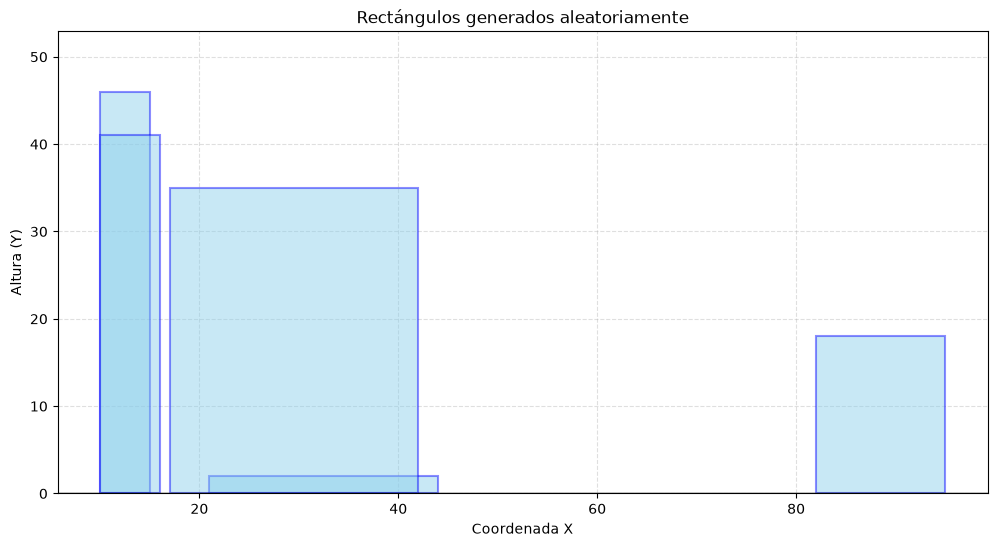

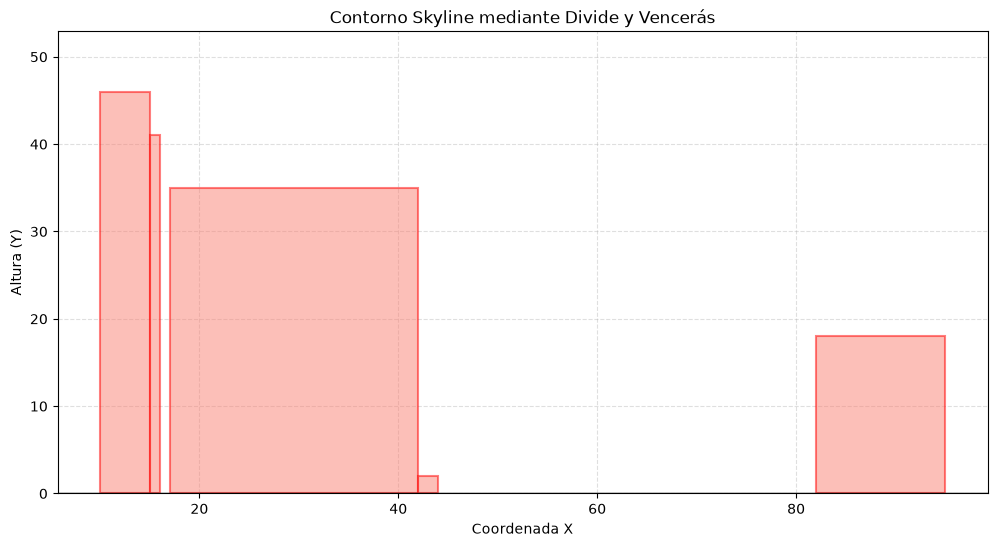

In [29]:
# Crear y almacenar las tripletas
rectangulos = crear_rectangulos()
franjasFuerzaBruta = fuerzaBruta(rectangulos)
franjasDivideVenceras = skyline_divide_venceras(rectangulos)

#datos de prueba
#rectangulos = [(1,11,5), (2,6,7), (3,13,9), (12,7,16), (14,3,25), (19,18,22)]
#franjas = [(1,11), (3,13), (9,0), (12,7), (16,3), (19,18), (22,3), (25,0)]

# Mostrar las tripletas ingresadas
print("\nTripletas almacenadas:")
print(rectangulos)

print("\nFranjas generadas por el algoritmo de fuerza bruta:")
print(franjasFuerzaBruta)

print("\nFranjas generadas por el algoritmo de divide y vencerás:")
print(franjasDivideVenceras)

# Dibujar los rectángulos
dibujar_rectangulos(rectangulos)
dibujar_contorno(franjasFuerzaBruta)
dibujar_contorno_divideVenceras(franjasDivideVenceras)
